In [ ]:
# Employee Attrition Analysis | HR Analytics Project

Project by: [RAM KUMAR]

About Dataset: 
IBM's HR dataset with information of 1470 employees. We have to find the pattern of employee who left the company.

What I have done in this notebook:
- Step 1: Cleaned the raw data (removed constant columns)
- Step 2: Calculated Important KPIs like Attrition Rate
- Step 3: Found Trends and Drivers of Attrition
- Step 4: Built a Random Forest Model to predict attrition
- Step 5: Created a tool to predict risk for a new employee
- Step 6: Gave Business Solutions to reduce attrition

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
%matplotlib inline


In [ ]:
## 1. Load & Clean the Data

Dataset source (working link):
`https://raw.githubusercontent.com/pplonski/datasets-for-start/refs/heads/master/employee_attrition/HR-Employee-Attrition-All.csv`

A local copy is also included at `data/HR-Employee-Attrition.csv` as a fallback.

DATA_URL = (
    "https://raw.githubusercontent.com/pplonski/datasets-for-start/"
    "refs/heads/master/employee_attrition/HR-Employee-Attrition-All.csv"
)
LOCAL_FALLBACK = "data/HR-Employee-Attrition.csv"

try:
    df = pd.read_csv(DATA_URL)
except Exception:
    df = pd.read_csv(LOCAL_FALLBACK)

df.columns = [c.strip() for c in df.columns]

# Drop constant columns (same value for every employee — no information)
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
df = df.drop(columns=constant_cols)
df = df.dropna()

print(f"Shape after cleaning: {df.shape}")
print(f"Dropped constant columns: {constant_cols}")
df.head()


Shape after cleaning: (1470, 32)
Dropped constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,4,1,6,3,3,2,2,2,2


## 2. Key Performance Indicators (KPIs)

In [3]:
total_employees = len(df)
attrition_rate = (df["Attrition"] == "Yes").mean()
avg_income = df["MonthlyIncome"].mean()
avg_tenure = df["YearsAtCompany"].mean()
avg_satisfaction = df["JobSatisfaction"].mean()
high_risk_share = ((df["OverTime"] == "Yes") & (df["JobSatisfaction"] <= 2)).mean()

print(f"Total Employees:            {total_employees}")
print(f"Attrition Rate:             {attrition_rate*100:.1f}%")
print(f"Avg Monthly Income:         ${avg_income:,.0f}")
print(f"Avg Years at Company:       {avg_tenure:.1f}")
print(f"Avg Job Satisfaction (1-4): {avg_satisfaction:.2f}")
print(f"High-Risk Employee Share:   {high_risk_share*100:.1f}%  (overtime + low satisfaction)")


Total Employees:            1470
Attrition Rate:             16.1%
Avg Monthly Income:         $6,503
Avg Years at Company:       7.0
Avg Job Satisfaction (1-4): 2.73
High-Risk Employee Share:   10.4%  (overtime + low satisfaction)


## 3. Trends & Drivers of Attrition

### 3.1 Attrition rate by department

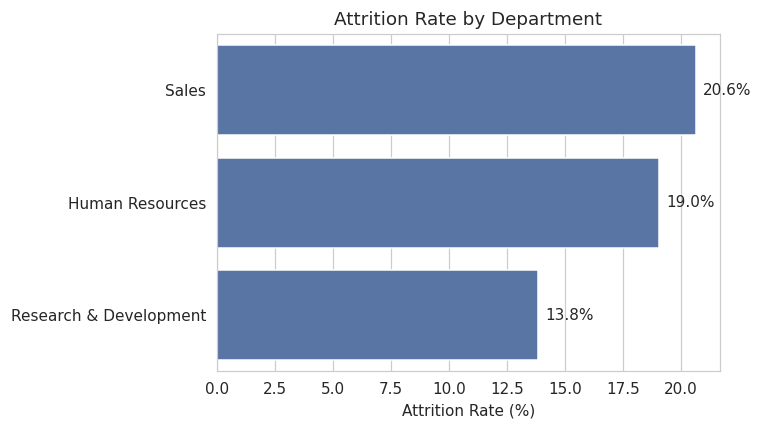

Department
Sales                     20.627803
Human Resources           19.047619
Research & Development    13.839750
Name: Attrition, dtype: float64

In [4]:
dept_attr = (
    df.groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=dept_attr.values, y=dept_attr.index, ax=ax, color="#4C72B0")
ax.set_xlabel("Attrition Rate (%)")
ax.set_ylabel("")
ax.set_title("Attrition Rate by Department")
for i, v in enumerate(dept_attr.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()

dept_attr


### 3.2 Highest-risk job roles

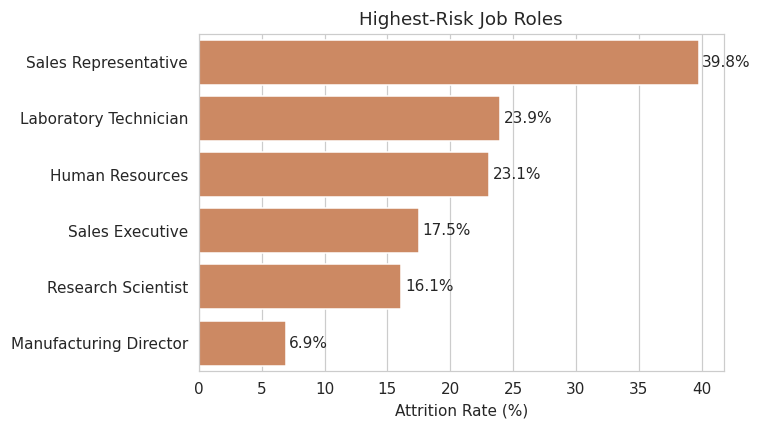

JobRole
Sales Representative         39.759036
Laboratory Technician        23.938224
Human Resources              23.076923
Sales Executive              17.484663
Research Scientist           16.095890
Manufacturing Director        6.896552
Healthcare Representative     6.870229
Manager                       4.901961
Research Director             2.500000
Name: Attrition, dtype: float64

In [5]:
role_attr = (
    df.groupby("JobRole")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
top_roles = role_attr.head(6)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=top_roles.values, y=top_roles.index, ax=ax, color="#DD8452")
ax.set_xlabel("Attrition Rate (%)")
ax.set_ylabel("")
ax.set_title("Highest-Risk Job Roles")
for i, v in enumerate(top_roles.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()

role_attr


### 3.3 Compensation as a driver — monthly income: stayed vs. left

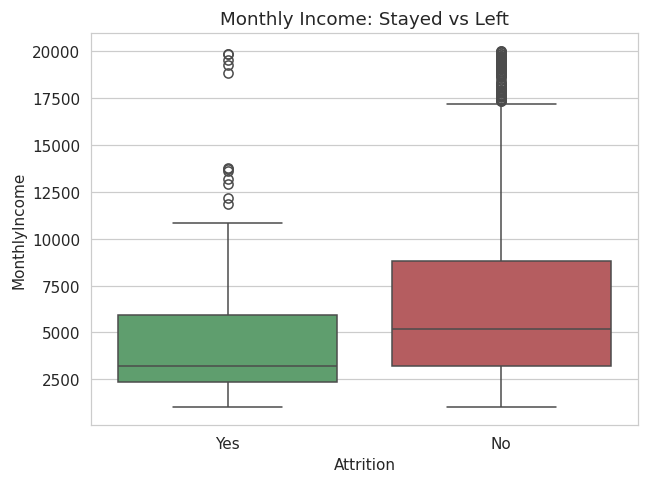

Attrition
No     5204.0
Yes    3202.0
Name: MonthlyIncome, dtype: float64

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome", hue="Attrition",
            palette=["#55A868", "#C44E52"], legend=False, ax=ax)
ax.set_title("Monthly Income: Stayed vs Left")
plt.tight_layout()
plt.show()

df.groupby("Attrition")["MonthlyIncome"].median()


### 3.4 Satisfaction and overtime

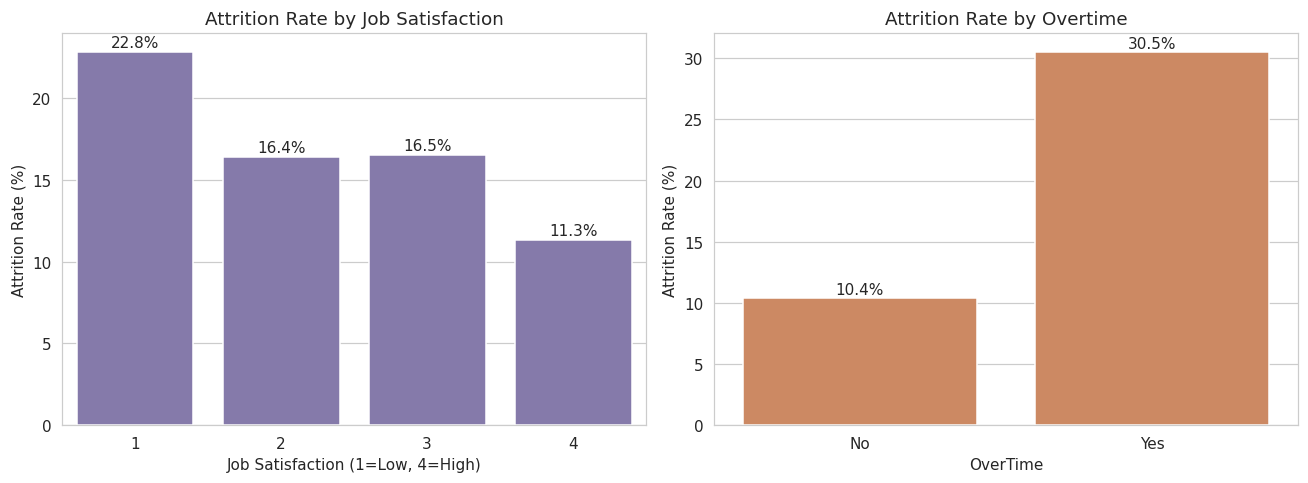

In [7]:
satisfaction_attr = df.groupby("JobSatisfaction")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)
overtime_attr = df.groupby("OverTime")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.barplot(x=satisfaction_attr.index, y=satisfaction_attr.values, ax=axes[0], color="#8172B2")
axes[0].set_xlabel("Job Satisfaction (1=Low, 4=High)")
axes[0].set_ylabel("Attrition Rate (%)")
axes[0].set_title("Attrition Rate by Job Satisfaction")
for i, v in enumerate(satisfaction_attr.values):
    axes[0].text(i, v + 0.3, f"{v:.1f}%", ha="center")

sns.barplot(x=overtime_attr.index, y=overtime_attr.values, ax=axes[1], color="#DD8452")
axes[1].set_ylabel("Attrition Rate (%)")
axes[1].set_title("Attrition Rate by Overtime")
for i, v in enumerate(overtime_attr.values):
    axes[1].text(i, v + 0.3, f"{v:.1f}%", ha="center")

plt.tight_layout()
plt.show()


## 4. Predictive Model — Random Forest Classifier

Predicts each employee's probability of attrition from their profile.
`EmployeeNumber` is dropped before training since it is just a record ID,
not a real feature — leaving it in would let the model "memorize" IDs
instead of learning genuine attrition patterns.

In [8]:
model_df = df.copy()
target = (model_df["Attrition"] == "Yes").astype(int)
model_df = model_df.drop(columns=["Attrition", "EmployeeNumber"])

cat_cols = model_df.select_dtypes(exclude=[np.number]).columns.tolist()
encoders = {}
for c in cat_cols:
    le = LabelEncoder()
    model_df[c] = le.fit_transform(model_df[c])
    encoders[c] = le

X_train, X_test, y_train, y_test = train_test_split(
    model_df, target, test_size=0.2, random_state=42, stratify=target
)

clf = RandomForestClassifier(
    n_estimators=300, max_depth=8, random_state=42, class_weight="balanced"
)
clf.fit(X_train, y_train)

pred = clf.predict(X_test)
proba = clf.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, pred)*100:.1f}%")
print(f"ROC-AUC:  {roc_auc_score(y_test, proba):.3f}")
print()
print(classification_report(y_test, pred, target_names=["Stayed", "Left"]))


Accuracy: 82.0%
ROC-AUC:  0.778

              precision    recall  f1-score   support

      Stayed       0.85      0.95      0.90       247
        Left       0.35      0.15      0.21        47

    accuracy                           0.82       294
   macro avg       0.60      0.55      0.55       294
weighted avg       0.77      0.82      0.79       294



### 4.1 Top drivers (feature importance)

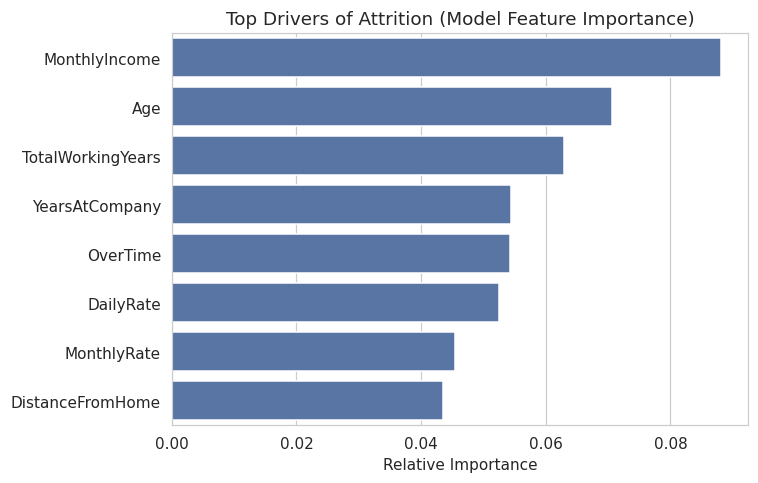

MonthlyIncome        0.088048
Age                  0.070700
TotalWorkingYears    0.062965
YearsAtCompany       0.054455
OverTime             0.054248
DailyRate            0.052523
MonthlyRate          0.045435
DistanceFromHome     0.043454
dtype: float64

In [9]:
feature_importance = pd.Series(clf.feature_importances_, index=model_df.columns).sort_values(ascending=False)
top_features = feature_importance.head(8)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=top_features.values, y=top_features.index, ax=ax, color="#4C72B0")
ax.set_xlabel("Relative Importance")
ax.set_ylabel("")
ax.set_title("Top Drivers of Attrition (Model Feature Importance)")
plt.tight_layout()
plt.show()

top_features


## 5. Risk Predictor — Score a New Employee

Edit the values in `new_employee` below to score any employee profile.

In [10]:
def predict_attrition_risk(profile: dict) -> float:
    """Return the model's predicted attrition probability (0-1) for an employee profile."""
    row = df.drop(columns=["Attrition"]).iloc[0].copy()
    for k, v in profile.items():
        row[k] = v

    row = row.drop(labels=["EmployeeNumber"])
    for c, le in encoders.items():
        if c in row.index:
            val = row[c]
            row[c] = le.transform([val])[0] if val in le.classes_ else 0

    X_input = row[model_df.columns].to_frame().T
    return clf.predict_proba(X_input)[0][1]


# Example: a Sales Representative working overtime with low satisfaction
new_employee = {
    "Age": 29,
    "Department": "Sales",
    "JobRole": "Sales Representative",
    "MonthlyIncome": 2800,
    "OverTime": "Yes",
    "JobSatisfaction": 1,
    "YearsAtCompany": 2,
}

risk = predict_attrition_risk(new_employee)
label = "HIGH RISK" if risk > 0.5 else ("MODERATE RISK" if risk > 0.3 else "LOW RISK")
print(f"Predicted attrition probability: {risk*100:.1f}%  -> {label}")


Predicted attrition probability: 55.0%  -> HIGH RISK


## 6. Business Insights Summary

**Risk**
- The department and role with the highest attrition carry the most urgent retention risk (see Section 3.1–3.2).
- Employees who work overtime **and** report low job satisfaction are the single highest-risk segment (~10% of the workforce).
- A clear pay gap exists between employees who stay and those who leave — compensation is a real driver, not just a correlate.

**Opportunity**
- Attrition drops sharply once job satisfaction rises above the lowest levels — even modest engagement gains could meaningfully cut turnover.
- The best-performing department shows low attrition is achievable; its practices are worth studying and replicating.
- The model above (Section 4) is accurate enough to flag at-risk employees proactively, before they resign.

**Recommended Actions**
1. Launch a targeted retention review (compensation + workload) for high-risk employees in the highest-attrition department, prioritizing overtime-heavy, low-satisfaction staff.
2. Introduce overtime caps or workload rebalancing in the highest-attrition role.
3. Run a compensation-band review for roles paid below the company's median income.
4. Operationalize the risk model as a quarterly HR early-warning report, flagging employees above a 50% predicted risk threshold for proactive manager check-ins.
